# Study: Does a weekly (7D) MACD trend signal predict BTC returns?

   Author: Darren Mark Effendy | NUS Quantitative Finance Y1 |

**Question.** On each day, the signal is the state of the 7D MACD (+1 when MACD is above its signal line, −1 when below), computed from **completed** weekly candles only. Does that state predict BTCUSDT's forward return over the next **h** days?

**Contents**

1. Library Initialization
2. Data: daily Binance candles, from 2018-01-01 to 2026-06-30.
3. Features: 7D MACD state, price-scaled histogram, and a lookahead test
4. Naive backtest: trade the signal, compared against buy-and-hold
5. Signal study: Newey-West regression, rank IC, quintiles, spread by year
6. Placebo bar: how big a t-stat a useless signal reaches on this data (shuffled bars so tomorrow's return has no association with today's)
7. Verdict

# 1.) Library Initialization

In [1]:
# Library & code to remove negligible warnings clogging the terminal

import warnings
negligible_warnings = [RuntimeWarning, UserWarning]
for warning in negligible_warnings:
    warnings.filterwarnings('ignore', category = warning, module='backtesting')
warnings.filterwarnings('ignore', category = UserWarning, module='bokeh')   # timezone notice from bt.plot

# Reloads macd_research/*.py automatically after edits (no kernel restart needed)

%load_ext autoreload
%autoreload 2

# Libraries for Data Manipulation

import numpy as np
import pandas as pd

# Library for Backtesting

from backtesting.lib import FractionalBacktest

# Library for Visualization

import matplotlib.pyplot as plt

# Research modules

from macd_research.data import (api, data_retrieval, find_ohlc, load_ohlc, BACKTEST_DIR,
                                end_date, eval_start, total_candles, cash, commission)
from macd_research.features import daily_features, run_lookahead_test
from macd_research.backtest import Naive_7DMACD_Strategy, save_backtest
from macd_research.stats import (forward_returns, state_regression, rank_ic,
                                 quintile_table, spread_by_year, placebo_bar, performance)
from macd_research.plots import plot_equity_to_closing_price

TICKER   = 'BTCUSDT'
HORIZONS = (5, 10, 20, 30, 40)     # fixed in advance

print('\n Update: Initialized Libraries [Cell Finished Running]')

Loading BokehJS ...


 Update: Intialized Libraries [Cell Finished Running]


# 2.) Binance Data Retrieval

Daily candles are downloaded once and saved to `data/01_OHLC_data`. `load_ohlc` refuses any file that doesn't match the current configuration (end date, row count, unique timestamps, start date).

Each row is labelled by the candle's **open** time (00:00 UTC); its close is known at 00:00 UTC the next day.

In [2]:
# Download only if no CSV matches the current configuration

if find_ohlc(TICKER) is not None:
    print(f"\n Update: {TICKER} data already exists — skipping download.")
else:
    data_retrieval(api, end_date, TICKER, total_candles)

data = load_ohlc(TICKER)

print("\n Update: OHLC data is ready [Cell Finished Running]")


 Update: BTCUSDT data already exists — skipping download.

 Update: Loaded BTCUSDT_1d_20180101_20260630.csv (3103 bars, 0 gaps)
 Data starts          : 2018-01-01 00:00:00+00:00
 Evaluation from      : 2018-12-31 00:00:00+00:00  to  2026-06-30 00:00:00+00:00

 Update: OHLC data is ready [Cell Finished Running]


# 3.) Features

`daily_features` builds weekly closes, computes MACD(12, 26, 9) on them, takes `state = sign(MACD − signal)` and `hist = (MACD − signal) / price`, then **shifts by one week** so each Monday only sees the last completed week, and forward-fills onto daily rows. The first 52 weeks are EMA warm-up bars: dates before `eval_start` are removed.

The Lookahead test shocks every close **after** day T with random noise and recomputes. If nothing at or before T changes, no value is used from data after T. The test also checks if any state/hist after T **does** change; if it doesn't, the test fails rather than passing by accident.

In [3]:
features = daily_features(data['Close'])

print(f" {features.index[0]:%Y-%m-%d} to {features.index[-1]:%Y-%m-%d}, % days in bullish state: "
      f"{(features['state'] > 0).mean() * 100:.0f}%")
print(features.head(10).to_string())

# Several cut dates, so the pass doesn't depend on one lucky T
for T in ['2019-06-30', '2021-03-15', '2022-06-30', '2024-11-05']:
    run_lookahead_test(data['Close'], T = T)
    print()

 2018-12-31 to 2026-06-30, % days in bullish state: 56%
                             close  state      hist
Timestamp                                          
2018-12-31 00:00:00+00:00  3702.90   -1.0 -0.040259
2019-01-01 00:00:00+00:00  3797.14   -1.0 -0.040259
2019-01-02 00:00:00+00:00  3858.56   -1.0 -0.040259
2019-01-03 00:00:00+00:00  3766.78   -1.0 -0.040259
2019-01-04 00:00:00+00:00  3792.01   -1.0 -0.040259
2019-01-05 00:00:00+00:00  3770.96   -1.0 -0.040259
2019-01-06 00:00:00+00:00  3987.60   -1.0 -0.040259
2019-01-07 00:00:00+00:00  3975.45   -1.0 -0.026241
2019-01-08 00:00:00+00:00  3955.13   -1.0 -0.026241
2019-01-09 00:00:00+00:00  3966.65   -1.0 -0.026241
=== Lookahead test: closes after 2019-06-30 shocked ===
        Rows <= T  Unchanged <= T  Changed > T
Series                                        
state         182            True         True
hist          182            True         True
LOOKAHEAD TEST PASSED

=== Lookahead test: closes after 2021-03-15 shocked =

# 4.) Naive Backtest

Long when the 7D MACD crosses above its signal line, short when it crosses below. No stop loss and no sizing rules: the signal is the only thing being tested. Orders fill at the **next day's open** with 0.1% commission per side; position sizes can be fractional BTC. No trades before `eval_start`.

This is not evidence. The following section 5. investigates whether a 7D-MACD has a real edge of if the results below come from 'luck'

In [4]:
# FractionalBacktest allows fractional BTC (whole-coin sizing would leave cash idle at $100k+ prices).
# It requires a Volume column; the strategy doesn't use volume, so zeros are fine.

bt = FractionalBacktest(data.assign(Volume = 0.0), Naive_7DMACD_Strategy,
                        cash = cash, commission = commission, finalize_trades = True, fractional_unit = 1e-6)
statistics = bt.run()

save_backtest(statistics, TICKER, 'naive_7d_macd')
bt.plot(filename = str(BACKTEST_DIR / f'{TICKER} naive 7D MACD.html'), resample = False, open_browser = False)

# Trade log with a Direction column

trades = statistics['_trades'].copy()
trades.insert(0, 'Direction', np.where(trades['Size'] > 0, 'Long', 'Short'))

print(f"\n Trades: {len(trades)}   First entry: {trades['EntryTime'].min():%Y-%m-%d}")
print(trades[['Direction', 'EntryTime', 'ExitTime', 'EntryPrice', 'ExitPrice', 'ReturnPct']].head(10).to_string())


 Trades: 24   First entry: 2019-02-12
  Direction                 EntryTime                  ExitTime  EntryPrice  ExitPrice  ReturnPct
0      Long 2019-02-12 00:00:00+00:00 2019-09-03 00:00:00+00:00     3631.05   10340.00   1.843813
1     Short 2019-09-03 00:00:00+00:00 2020-02-04 00:00:00+00:00    10340.00    9291.35   0.099518
2      Long 2020-02-04 00:00:00+00:00 2020-03-17 00:00:00+00:00     9291.35    5028.86  -0.460300
3     Short 2020-03-17 00:00:00+00:00 2020-05-05 00:00:00+00:00     5028.86    8871.92  -0.766965
4      Long 2020-05-05 00:00:00+00:00 2020-10-06 00:00:00+00:00     8871.92   10792.20   0.214228
5     Short 2020-10-06 00:00:00+00:00 2020-10-20 00:00:00+00:00    10792.20   11751.46  -0.090973
6      Long 2020-10-20 00:00:00+00:00 2021-04-27 00:00:00+00:00    11751.46   54001.38   3.589696
7     Short 2021-04-27 00:00:00+00:00 2021-08-24 00:00:00+00:00    54001.38   49488.85   0.081647
8      Long 2021-08-24 00:00:00+00:00 2021-12-07 00:00:00+00:00    49488.85   5

## 4a.) Does the backtest trade the same signal as the study?

The strategy computes its 7D MACD with `resample_apply`; the study uses `daily_features`. If they disagree on any day, the code has a bug; the backtest is trading a different signal than the study tests.

In [5]:
strategy = statistics['_strategy']
backtest_state = pd.Series(np.sign(np.asarray(strategy.macd) - np.asarray(strategy.signal_line)),
                           index = data.index).loc[eval_start:]

mismatches = int((backtest_state != features['state']).sum()) #Compares the Strategy and Study's signals.
print(f" Days where backtest signal != study signal: {mismatches}")

 Days where backtest signal != study signal: 0


## 4b.) Strategy vs Buy & Hold (evaluation period only)

backtesting.py's return, volatility, and Sharpe start on 2018-01-01; however, trading is only permitted after 2018-12-31 `eval_start`. To fix this issue, we remove the warmup period while calculating return, volatility and Sharpe Ratio. Since Trade statistics are unaffected, we take them directly from backtesting.py

In [6]:
strategy_equity = statistics['_equity_curve']['Equity'].loc[eval_start:] #Slice the warmup-year before eval_start to ensure correct calculation of Sharpe, return and Volatility
buy_and_hold    = data['Close'].loc[eval_start:]

comparison = pd.DataFrame({'7D MACD': performance(strategy_equity),
                           'Buy & Hold': performance(buy_and_hold)})
print('=== Evaluation period:', f'{eval_start:%Y-%m-%d} to {data.index[-1]:%Y-%m-%d} ===')
print(comparison.round(2).to_string())

# Trade statistics straight from backtesting.py

TRADE_KEYS = ['# Trades', 'Win Rate [%]', 'Profit Factor', 'Expectancy [%]',
              'Avg. Trade [%]', 'Max. Trade Duration', 'Avg. Trade Duration']
print('\n=== Trades ===')
print(statistics[[k for k in TRADE_KEYS if k in statistics]].to_string())

=== Evaluation period: 2018-12-31 to 2026-06-30 ===
                       7D MACD  Buy & Hold
Total return [%]        409.87     1483.21
Annual return [%]        24.25       44.51
Annual volatility [%]    60.49       61.98
Sharpe                    0.68        0.91
Max drawdown [%]        -90.57      -76.63

=== Trades ===
# Trades                              24
Win Rate [%]                   54.166667
Profit Factor                   3.690169
Expectancy [%]                 24.403585
Avg. Trade [%]                  7.014216
Max. Trade Duration    301 days 00:00:00
Avg. Trade Duration    113 days 00:00:00


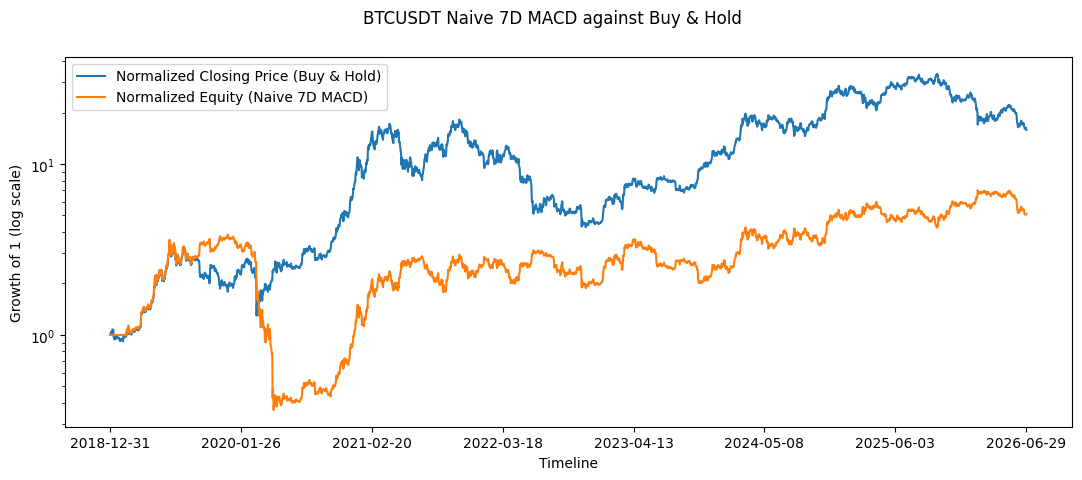

In [7]:
plot_equity_to_closing_price(data, statistics['_equity_curve'], TICKER)

# 5.) Signal Study

For each horizon *h*, every evaluation day is one row: its state, its histogram, and the % return from that day's close to the close *h* days later.

Forward returns overlap (a 20-day return shares 19 days with the next row's), so all t-stats use **Newey-West** errors with *h* − 1 lags.

In [8]:
def study_frame(features, h):
    ''' State, hist and h-day forward return per day; drops the last h days (no forward return) and state 0 '''
    d = pd.concat([features[['state', 'hist']],
                   forward_returns(features['close'], h).rename('fwd')], axis = 1).dropna() # Builds the pandas dataframe for our statistics test
    return d[d['state'] != 0] # only returns values where the state isnt 0

rows = []
for h in HORIZONS:
    d = study_frame(features, h)
    fit = state_regression(d, h)                 # 1. State regression. Intercept absorbs BTC drift; b is the signal
    ic = rank_ic(d, h)                           # 2. Rank IC of the histogram, HAC t on the ranked feature

    rows.append({'Horizon [d]': h,
                 'Days': len(d),
                 'Indep. obs ~': len(d) // h,
                 'Drift a [%]': fit.params['const'],
                 'State b [%]': fit.params['state'],
                 'Long-short 2b [%]': 2 * fit.params['state'],
                 't (HAC)': fit.tvalues['state'],
                 'Rank IC': ic['Rank IC'],
                 't IC (HAC)': ic['t IC (HAC)']})

summary = pd.DataFrame(rows).set_index('Horizon [d]')

print('\n=== 7D MACD as a daily feature ===')
print(summary.round(2).to_string())


=== 7D MACD as a daily feature ===
             Days  Indep. obs ~  Drift a [%]  State b [%]  Long-short 2b [%]  t (HAC)  Rank IC  t IC (HAC)
Horizon [d]                                                                                               
5            2734           546         0.70         0.52               1.03     2.08     0.05        2.04
10           2729           272         1.41         1.13               2.26     2.24     0.06        2.02
20           2719           135         2.99         2.20               4.40     2.12     0.08        1.81
30           2709            90         4.67         2.87               5.73     1.86     0.09        1.66
40           2699            67         6.54         3.69               7.37     1.76     0.12        1.58


## 5a.) Quintiles: is the relationship monotonic?

Days are split into five equal groups by `hist` (1 = most bearish trend, 5 = most bullish). Bin edges use the full sample, so this table is descriptive, not a tradeable rule.

In [9]:
for h in HORIZONS: #Splits Hist signal strength into five quintiles, from most bearish to most bullish, and displays the h-day average return, median etc..
    print(f'\n--- {h}d forward return by histogram quintile (1 = most bearish) ---')
    print(quintile_table(study_frame(features, h)).round(2).to_string())


--- 5d forward return by histogram quintile (1 = most bearish) ---
          count  mean  median
Quintile                     
1           553  0.86    0.92
2           546 -0.40   -0.08
3           543  0.86    0.30
4           546  0.16    0.11
5           546  2.32    1.32

--- 10d forward return by histogram quintile (1 = most bearish) ---
          count  mean  median
Quintile                     
1           546  1.61    1.38
2           546 -0.86   -1.08
3           545  2.06    0.90
4           546  0.16    0.02
5           546  4.76    2.27

--- 20d forward return by histogram quintile (1 = most bearish) ---
          count  mean  median
Quintile                     
1           546  3.07    2.25
2           546 -1.13   -0.32
3           542  3.94    0.68
4           546  0.78    0.38
5           539  9.69    4.22

--- 30d forward return by histogram quintile (1 = most bearish) ---
          count   mean  median
Quintile                      
1           546   5.15    3.91
2 

## 5b.) Stability: bull-minus-bear spread by year

Each day counts in the year its forward return starts. Single years hold only a handful of state flips, so read the **signs**, not the sizes.

In [10]:
#Stability: long-short spread per calendar year: shows the following h(mid) day returns after a bear and bull signal

h_mid = HORIZONS[len(HORIZONS) // 2]
by_year = spread_by_year(study_frame(features, h_mid)).loc[eval_start.year + 1:]   # drop the 1-day 2018 stub

print(f'\n--- {h_mid}d mean return by year and state (Spread = bull - bear) ---')
print(by_year.round(2).to_string())
print(f"\n Spread > 0 in {(by_year['Spread'] > 0).sum()} of {by_year['Spread'].notna().sum()} years")


--- 20d mean return by year and state (Spread = bull - bear) ---
state   -1.0    1.0   Spread
Year                        
2019   -1.93  11.85    13.78
2020   17.40   7.87    -9.53
2021   -1.54   5.59     7.12
2022   -4.09  -2.92     1.16
2023    7.46   4.60    -2.85
2024    1.35   8.66     7.31
2025   -0.30   0.46     0.76
2026   -2.20  -7.86    -5.66

 Spread > 0 in 5 of 8 years


# 6.) Placebo Bar

Shuffle BTC's real daily returns (same returns, random order, so no trends exist), rebuild a price path, and rerun the **identical** pipeline. Repeat 300 times. The 95th percentile of |t| is the bar a useless signal reaches only 5% of the time on data like this.

Limitation: shuffling also removes volatility clustering, so the bar may be slightly too low.

In [11]:
placebo = placebo_bar(data['Close'], horizons = HORIZONS, n_paths = 300)

print('\n=== Placebo: shuffled returns, no signal by construction ===')
print(placebo.round(2).to_string())


=== Placebo: shuffled returns, no signal by construction ===
             P(|t| > 2) under null  95th pct |t| (bar)
Horizon [d]                                           
5                             0.12                2.48
10                            0.10                2.50
20                            0.11                2.56
30                            0.11                2.53
40                            0.12                2.60


# 7.) Verdict

In [12]:
# Your t against the placebo bar instead of 2

verdict = summary[['State b [%]', 't (HAC)']].join(placebo['95th pct |t| (bar)'])
verdict['Clears placebo bar'] = verdict['t (HAC)'].abs() > verdict['95th pct |t| (bar)']

print('\n=== Does the 7D state clear the placebo bar? ===')
print(verdict.round(2).to_string())
print(f"\n b > 0 at {(verdict['State b [%]'] > 0).sum()} of {len(verdict)} horizons"
      f"   |   clears placebo bar at {verdict['Clears placebo bar'].sum()} of {len(verdict)}")


=== Does the 7D state clear the placebo bar? ===
             State b [%]  t (HAC)  95th pct |t| (bar)  Clears placebo bar
Horizon [d]                                                              
5                   0.52     2.08                2.48               False
10                  1.13     2.24                2.50               False
20                  2.20     2.12                2.56               False
30                  2.87     1.86                2.53               False
40                  3.69     1.76                2.60               False

 b > 0 at 5 of 5 horizons   |   clears placebo bar at 0 of 5


Under the conventional |t| > 2 rule, a useless signal should pass about 5% of the time; here it passes 10–12% of the time, so the placebo bar (the |t| that useless signals exceed only 5% of the time) is used instead. The t(HAC) value clears it at 0 of 5 horizons. Although the effect is positive at every horizon, it is not distinguishable from chance in this sample (null result).